# Comparaison de modèles séquentiels (LSTM pré-entraîné, GRU, Attention)

## Données et préparation des séries temporelles
La première étape a consisté à constituer et préparer les données de prix du Bitcoin. J’ai rassemblé plusieurs années d’historique des cours du Bitcoin (principalement les prix de clôture quotidiens) afin d’avoir une base solide pour l’entraînement et les tests. 

Travailler avec des données financières brutes nécessite souvent quelques transformations : dans mon cas, j’ai appliqué une normalisation des prix (par exemple via une échelle 0-1) pour faciliter l’apprentissage du réseau de neurones. Normaliser les données permet d’éviter les problèmes d’échelles trop différentes et aide les modèles à converger plus rapidement. 

Pour exploiter les données de prix sous forme séquentielle, j’ai mis en place une technique de fenêtrage temporel (*sequence windowing* en anglais). Concrètement, au lieu de donner toute la série d’un coup au réseau, on découpe la série en segments de longueur fixe (appelés “fenêtres glissantes”). Par exemple, j’ai utilisé des fenêtres de 30 jours : le modèle reçoit en entrée les prix des 30 jours consécutifs, et il doit prédire le prix du jour suivant. Puis la fenêtre glisse d’un jour (jours 2 à 31 pour prédire le 32e, etc.) afin de générer autant d’exemples d’entraînement que possible. 

Ce procédé transforme la tâche de prédiction de série temporelle en un problème de *supervised learning* classique avec des paires $(X, y)$, $X$ étant un segment de série temporelle et $y$ la valeur cible à prédire. J’ai séparé les données en un ensemble d’entraînement (en gros, les premières années de données), un ensemble de validation (pour tester les modèles en cours de mise au point et ajuster leurs hyperparamètres), et un ensemble de test final contenant les données les plus récentes, pour évaluer objectivement les performances sur des données encore jamais vues par le modèle.

## Modèles séquentiels comparés
Dans ce projet, j’ai implémenté et entraîné trois types de modèles séquentiels différents pour comparer leurs performances :

### 1. LSTM (Long Short-Term Memory)
Ce type de réseau de neurones récurrent comporte des mécanismes internes appelés portes (d’oubli, d’entrée et de sortie) qui lui permettent de conserver de l’information sur de longues séquences sans que le signal ne disparaisse ou n’explose. Intuitivement, un LSTM peut décider de “retenir” certaines tendances importantes du passé lointain tout en oubliant les fluctuations bruitées. Les LSTM sont depuis longtemps utilisés avec succès pour des séries temporelles, justement parce qu’ils gèrent bien la dépendance à long terme. Dans mon implémentation, j’ai utilisé une couche LSTM pouvant traiter les séquences de 30 jours et produire une représentation interne qui servira à prédire le jour suivant.

### 2. GRU (Gated Recurrent Unit)
Le GRU est une variante plus récente et simplifiée du LSTM. Il dispose également de mécanismes de porte, mais en moins grand nombre (il combine certaines portes et réduit le nombre de paramètres). En pratique, un GRU tend à être plus simple et un peu plus rapide à entraîner qu’un LSTM, tout en obtenant souvent des performances comparables. Je souhaitais vérifier cela par moi-même sur les données du Bitcoin. J’ai donc entraîné un modèle GRU de configuration équivalente au LSTM (même taille de vecteur caché, etc.) pour voir s’il pouvait rivaliser en précision tout en potentiellement évitant le surapprentissage grâce à sa structure plus légère.

### 3. Modèle à Attention
Pour ce troisième modèle, j’ai intégré un mécanisme d’attention par-dessus un réseau récurrent. Concrètement, j’ai adopté une architecture de type encodeur-décodeur inspirée de celle utilisée en traduction automatique. Le encodeur est un réseau LSTM qui lit la séquence de 30 jours et en tire une série de représentations intermédiaires (un vecteur par jour, encapsulant l’information de ce jour compte tenu du contexte précédent). Au lieu de seulement prendre le dernier vecteur (dernier état caché) comme le font classiquement les RNN, j’ai ajouté un module d’attention qui va pondérer l’ensemble de ces vecteurs journaliers. 

L’idée est de permettre au modèle de sélectionner et de mettre l’accent sur les jours les plus pertinents pour la prédiction à venir. Chaque jour dans la fenêtre se voit attribuer un poids (une importance) calculé par le mécanisme d’attention, et le modèle calcule alors une combinaison pondérée de ces vecteurs pour produire la prédiction finale. Ainsi, si par exemple un brusque mouvement de prix il y a 10 jours est particulièrement informatif pour aujourd’hui, le mécanisme d’attention peut lui donner un poids élevé dans la décision. Ce modèle à attention est une étape intermédiaire vers les Transformers : il conserve la structure d’un RNN classique, mais y adjoint une couche d’attention pour potentiellement améliorer la performance et la lisibilité des prédictions.

In [5]:
import sys
import pandas as pd
import torch
import torch.nn as nn

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 10)

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

# Chemin vers les scripts
sys.path.append("../src/")
sys.path.append("../models/")

from src.preprocess import load_and_filter_data, train_val_test_split, prepare_datasets, numpy_to_torch
from src.train import train_model
from src.evaluate import predict, compute_metrics
from src.visualization import plot_loss, plot_predictions_compare, plot_prediction_lstm, barplot_metrics

from models.lstm_model import LSTMModel
from models.gru_model import GRUModel
from models.attention_model import AttentionModel

device = torch.device("cuda")
print("Device utilisé:", device)

Device utilisé: cuda


---
1. Chargement du CSV univarié
---

<>:1: SyntaxWarning: invalid escape sequence '\B'
<>:1: SyntaxWarning: invalid escape sequence '\B'
C:\Users\mehdi\AppData\Local\Temp\ipykernel_14440\1880889411.py:1: SyntaxWarning: invalid escape sequence '\B'
  csv_path = "data\BTC.csv"


Aperçu df :
                 close
date                  
2015-01-01  314.248993
2015-01-02  315.032013
2015-01-03  281.082001
2015-01-04  264.195007
2015-01-05  274.473999
Shape : (3732, 1)


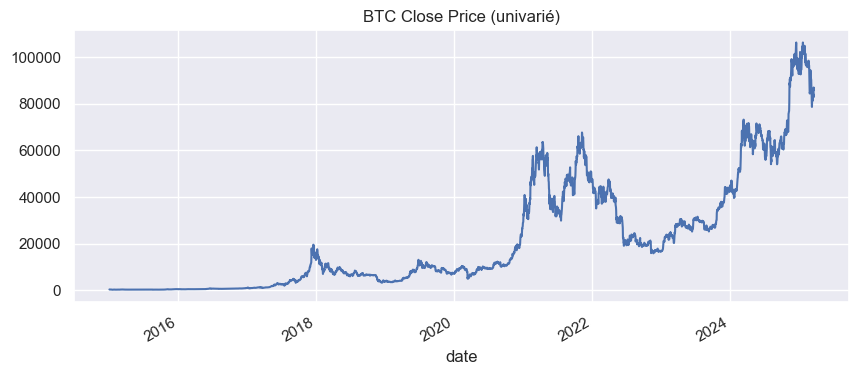

In [6]:
csv_path = "data\BTC.csv"
df = load_and_filter_data(csv_path)

print("Aperçu df :")
print(df.head())
print("Shape :", df.shape)

# Affiche un mini-graph du Close
df['close'].plot(title="BTC Close Price (univarié)", figsize=(10,4))
plt.show()


---
2. Split train/val/test
---

In [7]:
# Split
df_train, df_val, df_test = train_val_test_split(df, 0.8, 0.1)
print("Train set size:", len(df_train))
print("Val set size:  ", len(df_val))
print("Test set size: ", len(df_test))

Train set size: 2985
Val set size:   373
Test set size:  374


---
3. Fenêtrage (1 feature)
---

In [8]:
window_size = 30
horizons = [1, 3, 7]
datasets = {}

for h in horizons:
    X_train, y_train, X_val, y_val, X_test, y_test, scaler = prepare_datasets(
        df_train, df_val, df_test,
        window_size=window_size, horizon=h
    )
    datasets[h] = {
        'X_train': X_train,
        'y_train': y_train,
        'X_val':   X_val,
        'y_val':   y_val,
        'X_test':  X_test,
        'y_test':  y_test,
        'scaler':  scaler
    }

---
4. Charger le LSTM pré-entraîné
---

In [9]:
import json
import torch
import torch.nn as nn

lstm_config_path = r"LSTM\config.json"
lstm_weights_path = r"LSTM\pytorch_model.bin"

with open(lstm_config_path, 'r') as f:
    config_lstm = json.load(f)

print("Config LSTM pré-entraîné:", config_lstm)

pretrained_lstm = LSTMModel(
    input_dim=config_lstm["input_dim"],   # ex: 1
    hidden_dim=config_lstm["hidden_dim"],
    num_layers=config_lstm["num_layers"],
    output_dim=config_lstm["output_dim"]
)

# Charger le checkpoint (sauvegardé avec input_dim=1)
state_dict = torch.load(lstm_weights_path, map_location='cpu')
pretrained_lstm.load_state_dict(state_dict)
pretrained_lstm.eval()
print("LSTM pré-entraîné chargé avec succès.")

Config LSTM pré-entraîné: {'input_dim': 1, 'hidden_dim': 64, 'num_layers': 5, 'output_dim': 1, 'num_epochs': 500}
LSTM pré-entraîné chargé avec succès.


---
5. Entraînement: LSTM, GRU, Attention
---

In [11]:
input_dim  = config_lstm["input_dim"]   # 1
hidden_dim = config_lstm["hidden_dim"]  # 64
num_layers = config_lstm["num_layers"]  # 5
output_dim = config_lstm["output_dim"]  # 1

=== Entraînement LSTM (from scratch) - horizon=1 ===
[Epoch 1/50] train_loss=0.037536, val_loss=0.005939
[Epoch 2/50] train_loss=0.002126, val_loss=0.003260
[Epoch 3/50] train_loss=0.001229, val_loss=0.002153
[Epoch 4/50] train_loss=0.001012, val_loss=0.001789
[Epoch 5/50] train_loss=0.001040, val_loss=0.001007
[Epoch 6/50] train_loss=0.000704, val_loss=0.001691
[Epoch 7/50] train_loss=0.000654, val_loss=0.001253
[Epoch 8/50] train_loss=0.000707, val_loss=0.000559
[Epoch 9/50] train_loss=0.000593, val_loss=0.000940
[Epoch 10/50] train_loss=0.000539, val_loss=0.000533
[Epoch 11/50] train_loss=0.000423, val_loss=0.000543
[Epoch 12/50] train_loss=0.000410, val_loss=0.001035
[Epoch 13/50] train_loss=0.000555, val_loss=0.000490
[Epoch 14/50] train_loss=0.000372, val_loss=0.000945
[Epoch 15/50] train_loss=0.000316, val_loss=0.000434
[Epoch 16/50] train_loss=0.000253, val_loss=0.000442
[Epoch 17/50] train_loss=0.000362, val_loss=0.000273
[Epoch 18/50] train_loss=0.000280, val_loss=0.000480
[E

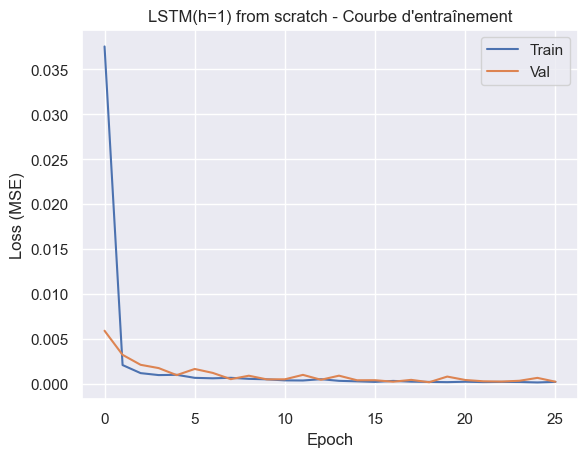

=== Entraînement GRU (from scratch) - horizon=1 ===
[Epoch 1/50] train_loss=0.010789, val_loss=0.001932
[Epoch 2/50] train_loss=0.000680, val_loss=0.000765
[Epoch 3/50] train_loss=0.000474, val_loss=0.001633
[Epoch 4/50] train_loss=0.000393, val_loss=0.000565
[Epoch 5/50] train_loss=0.000382, val_loss=0.000516
[Epoch 6/50] train_loss=0.000311, val_loss=0.000780
[Epoch 7/50] train_loss=0.000295, val_loss=0.000301
[Epoch 8/50] train_loss=0.000367, val_loss=0.000283
[Epoch 9/50] train_loss=0.000342, val_loss=0.000430
[Epoch 10/50] train_loss=0.000261, val_loss=0.000260
[Epoch 11/50] train_loss=0.000226, val_loss=0.001256
[Epoch 12/50] train_loss=0.000292, val_loss=0.000202
[Epoch 13/50] train_loss=0.000243, val_loss=0.000509
[Epoch 14/50] train_loss=0.000227, val_loss=0.000445
[Epoch 15/50] train_loss=0.000289, val_loss=0.000507
[Epoch 16/50] train_loss=0.000298, val_loss=0.000431
[Epoch 17/50] train_loss=0.000230, val_loss=0.000383
[Epoch 18/50] train_loss=0.000204, val_loss=0.000305
[Ep

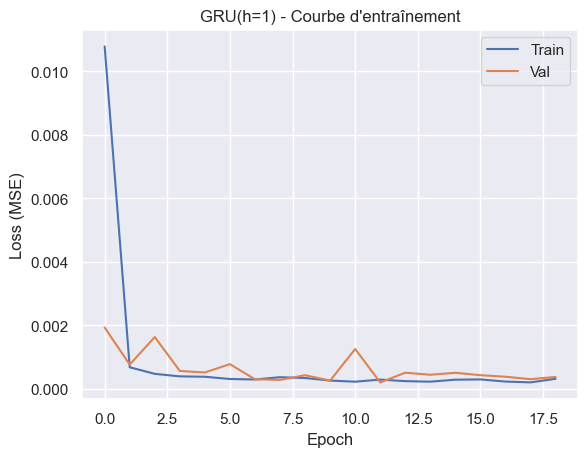

=== Entraînement Attention (from scratch) - horizon=1 ===
[Epoch 1/80] train_loss=0.026886, val_loss=0.023839
[Epoch 2/80] train_loss=0.003754, val_loss=0.011898
[Epoch 3/80] train_loss=0.002985, val_loss=0.005647
[Epoch 4/80] train_loss=0.002624, val_loss=0.004756
[Epoch 5/80] train_loss=0.002650, val_loss=0.004190
[Epoch 6/80] train_loss=0.002414, val_loss=0.005111
[Epoch 7/80] train_loss=0.002363, val_loss=0.004676
[Epoch 8/80] train_loss=0.002353, val_loss=0.003601
[Epoch 9/80] train_loss=0.001816, val_loss=0.002805
[Epoch 10/80] train_loss=0.001891, val_loss=0.004527
[Epoch 11/80] train_loss=0.001769, val_loss=0.006160
[Epoch 12/80] train_loss=0.001785, val_loss=0.002206
[Epoch 13/80] train_loss=0.001141, val_loss=0.001259
[Epoch 14/80] train_loss=0.001262, val_loss=0.001475
[Epoch 15/80] train_loss=0.000939, val_loss=0.001157
[Epoch 16/80] train_loss=0.000905, val_loss=0.001106
[Epoch 17/80] train_loss=0.000725, val_loss=0.001696
[Epoch 18/80] train_loss=0.000700, val_loss=0.0008

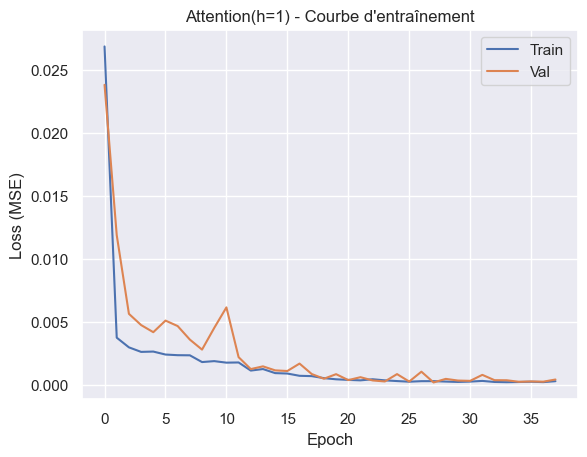

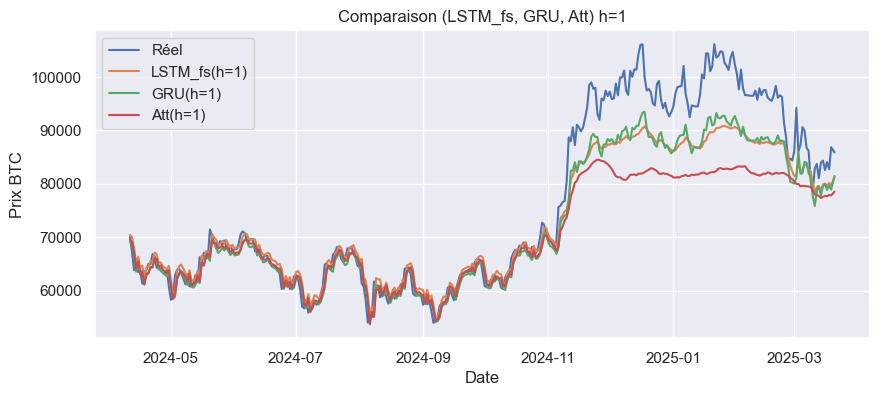

=== Entraînement LSTM (from scratch) - horizon=3 ===
[Epoch 1/50] train_loss=0.031792, val_loss=0.005131
[Epoch 2/50] train_loss=0.002201, val_loss=0.004535
[Epoch 3/50] train_loss=0.001640, val_loss=0.002746
[Epoch 4/50] train_loss=0.001305, val_loss=0.003822
[Epoch 5/50] train_loss=0.001314, val_loss=0.002508
[Epoch 6/50] train_loss=0.001223, val_loss=0.004771
[Epoch 7/50] train_loss=0.001234, val_loss=0.006595
[Epoch 8/50] train_loss=0.001285, val_loss=0.001387
[Epoch 9/50] train_loss=0.000902, val_loss=0.001967
[Epoch 10/50] train_loss=0.000780, val_loss=0.001164
[Epoch 11/50] train_loss=0.000907, val_loss=0.001098
[Epoch 12/50] train_loss=0.000747, val_loss=0.001226
[Epoch 13/50] train_loss=0.000669, val_loss=0.001282
[Epoch 14/50] train_loss=0.000766, val_loss=0.003233
[Epoch 15/50] train_loss=0.000859, val_loss=0.000833
[Epoch 16/50] train_loss=0.000607, val_loss=0.000712
[Epoch 17/50] train_loss=0.000626, val_loss=0.000992
[Epoch 18/50] train_loss=0.000563, val_loss=0.000808
[E

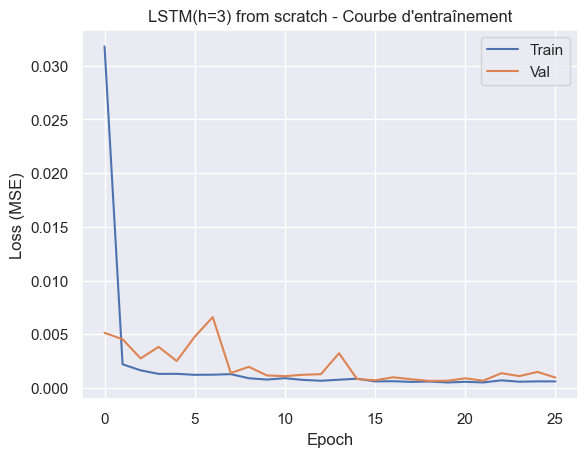

=== Entraînement GRU (from scratch) - horizon=3 ===
[Epoch 1/50] train_loss=0.016589, val_loss=0.001825
[Epoch 2/50] train_loss=0.000899, val_loss=0.001164
[Epoch 3/50] train_loss=0.000797, val_loss=0.003014
[Epoch 4/50] train_loss=0.000854, val_loss=0.000898
[Epoch 5/50] train_loss=0.000653, val_loss=0.001802
[Epoch 6/50] train_loss=0.000735, val_loss=0.001366
[Epoch 7/50] train_loss=0.000654, val_loss=0.000932
[Epoch 8/50] train_loss=0.000776, val_loss=0.000690
[Epoch 9/50] train_loss=0.000573, val_loss=0.000989
[Epoch 10/50] train_loss=0.000612, val_loss=0.001085
[Epoch 11/50] train_loss=0.000570, val_loss=0.000679
[Epoch 12/50] train_loss=0.000638, val_loss=0.000913
[Epoch 13/50] train_loss=0.000617, val_loss=0.000641
[Epoch 14/50] train_loss=0.000507, val_loss=0.000640
[Epoch 15/50] train_loss=0.000628, val_loss=0.000873
[Epoch 16/50] train_loss=0.000497, val_loss=0.000806
[Epoch 17/50] train_loss=0.000511, val_loss=0.000616
[Epoch 18/50] train_loss=0.000543, val_loss=0.001543
[Ep

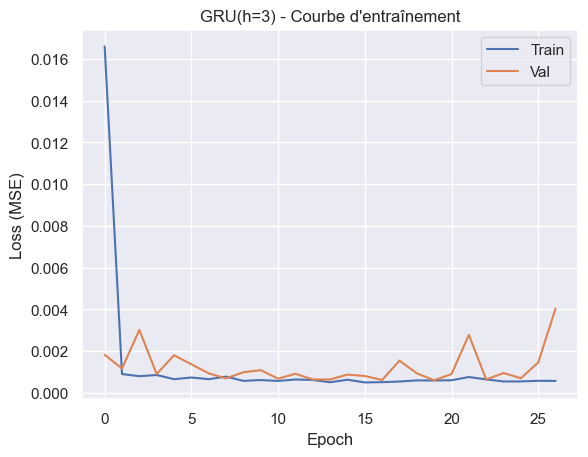

=== Entraînement Attention (from scratch) - horizon=3 ===
[Epoch 1/80] train_loss=0.027314, val_loss=0.011211
[Epoch 2/80] train_loss=0.003787, val_loss=0.014667
[Epoch 3/80] train_loss=0.003452, val_loss=0.008333
[Epoch 4/80] train_loss=0.002895, val_loss=0.005372
[Epoch 5/80] train_loss=0.003296, val_loss=0.010587
[Epoch 6/80] train_loss=0.003130, val_loss=0.004045
[Epoch 7/80] train_loss=0.002536, val_loss=0.004427
[Epoch 8/80] train_loss=0.002956, val_loss=0.004305
[Epoch 9/80] train_loss=0.002328, val_loss=0.005046
[Epoch 10/80] train_loss=0.002198, val_loss=0.006617
[Epoch 11/80] train_loss=0.002125, val_loss=0.003596
[Epoch 12/80] train_loss=0.001724, val_loss=0.002828
[Epoch 13/80] train_loss=0.001573, val_loss=0.001775
[Epoch 14/80] train_loss=0.001560, val_loss=0.003366
[Epoch 15/80] train_loss=0.001578, val_loss=0.004487
[Epoch 16/80] train_loss=0.001527, val_loss=0.002311
[Epoch 17/80] train_loss=0.001523, val_loss=0.003716
[Epoch 18/80] train_loss=0.001561, val_loss=0.0027

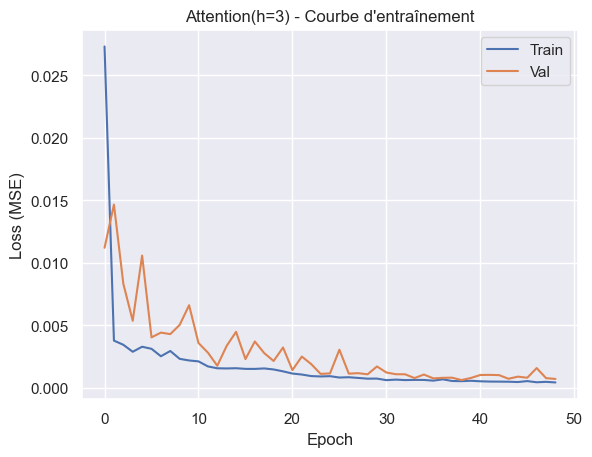

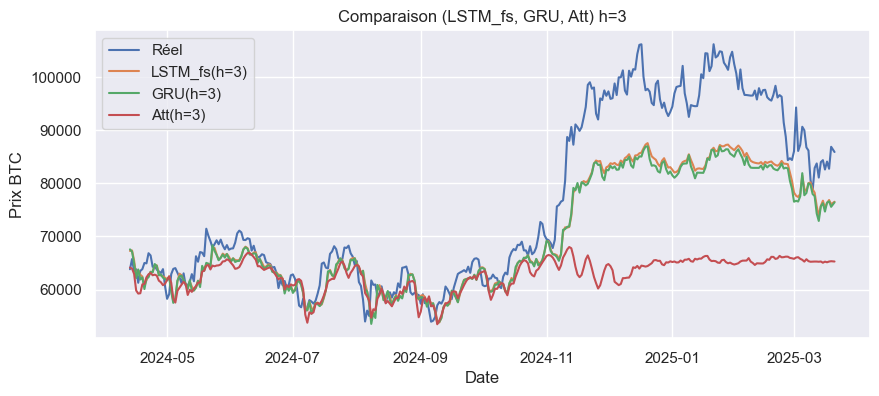

=== Entraînement LSTM (from scratch) - horizon=7 ===
[Epoch 1/50] train_loss=0.018906, val_loss=0.007560
[Epoch 2/50] train_loss=0.002834, val_loss=0.004312
[Epoch 3/50] train_loss=0.002676, val_loss=0.003646
[Epoch 4/50] train_loss=0.002534, val_loss=0.006721
[Epoch 5/50] train_loss=0.002245, val_loss=0.004310
[Epoch 6/50] train_loss=0.002151, val_loss=0.002672
[Epoch 7/50] train_loss=0.001936, val_loss=0.005750
[Epoch 8/50] train_loss=0.001779, val_loss=0.003004
[Epoch 9/50] train_loss=0.001772, val_loss=0.002821
[Epoch 10/50] train_loss=0.001603, val_loss=0.002742
[Epoch 11/50] train_loss=0.001570, val_loss=0.002390
[Epoch 12/50] train_loss=0.001484, val_loss=0.005112
[Epoch 13/50] train_loss=0.001643, val_loss=0.003441
[Epoch 14/50] train_loss=0.001502, val_loss=0.002309
[Epoch 15/50] train_loss=0.001409, val_loss=0.001859
[Epoch 16/50] train_loss=0.001313, val_loss=0.002956
[Epoch 17/50] train_loss=0.001438, val_loss=0.002075
[Epoch 18/50] train_loss=0.001199, val_loss=0.002017
[E

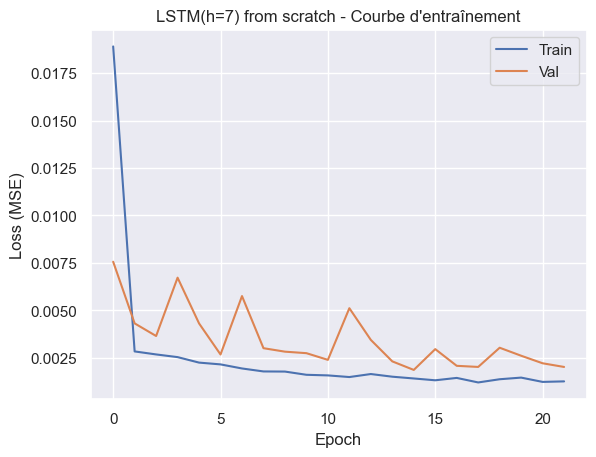

=== Entraînement GRU (from scratch) - horizon=7 ===
[Epoch 1/50] train_loss=0.016944, val_loss=0.003489
[Epoch 2/50] train_loss=0.001847, val_loss=0.006454
[Epoch 3/50] train_loss=0.001603, val_loss=0.002219
[Epoch 4/50] train_loss=0.001456, val_loss=0.002260
[Epoch 5/50] train_loss=0.001285, val_loss=0.003786
[Epoch 6/50] train_loss=0.001357, val_loss=0.001962
[Epoch 7/50] train_loss=0.001249, val_loss=0.001867
[Epoch 8/50] train_loss=0.001303, val_loss=0.002490
[Epoch 9/50] train_loss=0.001567, val_loss=0.003397
[Epoch 10/50] train_loss=0.001200, val_loss=0.001890
[Epoch 11/50] train_loss=0.001126, val_loss=0.001757
[Epoch 12/50] train_loss=0.001291, val_loss=0.001617
[Epoch 13/50] train_loss=0.001230, val_loss=0.001694
[Epoch 14/50] train_loss=0.001275, val_loss=0.001741
[Epoch 15/50] train_loss=0.001323, val_loss=0.002338
[Epoch 16/50] train_loss=0.001173, val_loss=0.001782
[Epoch 17/50] train_loss=0.001157, val_loss=0.002006
[Epoch 18/50] train_loss=0.001430, val_loss=0.004477
[Ep

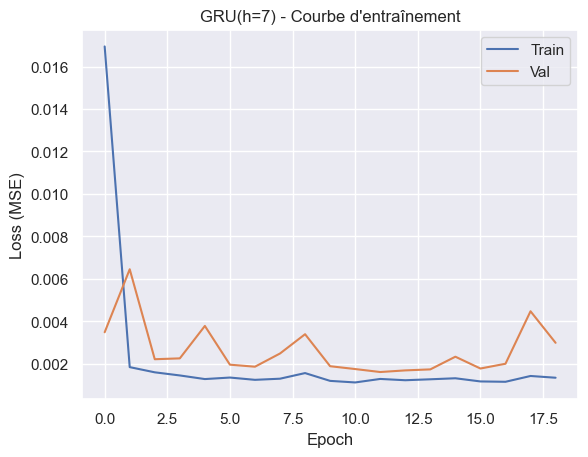

=== Entraînement Attention (from scratch) - horizon=7 ===
[Epoch 1/80] train_loss=0.026380, val_loss=0.021747
[Epoch 2/80] train_loss=0.005420, val_loss=0.010709
[Epoch 3/80] train_loss=0.004217, val_loss=0.007474
[Epoch 4/80] train_loss=0.004164, val_loss=0.007688
[Epoch 5/80] train_loss=0.003486, val_loss=0.012675
[Epoch 6/80] train_loss=0.003549, val_loss=0.007514
[Epoch 7/80] train_loss=0.003825, val_loss=0.012066
[Epoch 8/80] train_loss=0.003306, val_loss=0.004801
[Epoch 9/80] train_loss=0.003255, val_loss=0.008028
[Epoch 10/80] train_loss=0.003217, val_loss=0.004086
[Epoch 11/80] train_loss=0.003226, val_loss=0.007688
[Epoch 12/80] train_loss=0.002832, val_loss=0.004024
[Epoch 13/80] train_loss=0.002534, val_loss=0.003747
[Epoch 14/80] train_loss=0.002103, val_loss=0.003146
[Epoch 15/80] train_loss=0.002233, val_loss=0.002744
[Epoch 16/80] train_loss=0.001765, val_loss=0.005220
[Epoch 17/80] train_loss=0.001716, val_loss=0.002922
[Epoch 18/80] train_loss=0.001627, val_loss=0.0021

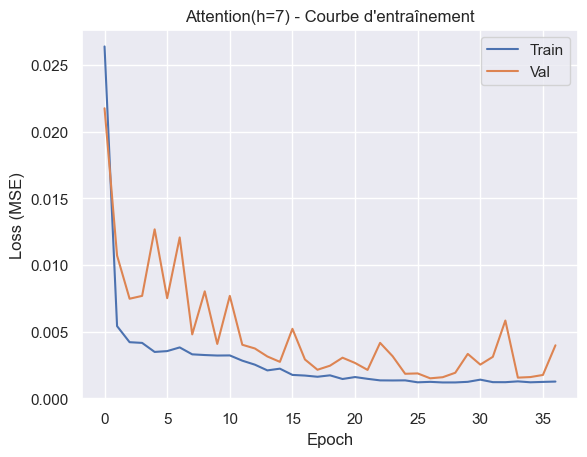

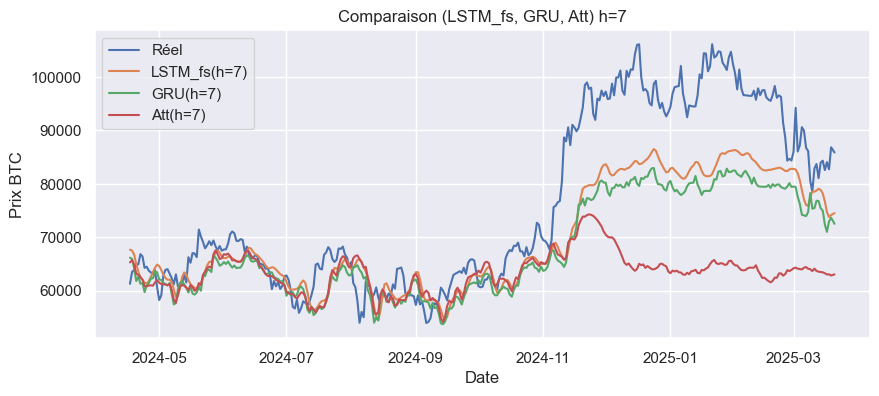

In [13]:
# Configs LSTM
lstm_train_cfg = {
    "lr": 1e-3,
    "epochs": 50,
    "patience": 7
}
# Configs GRU
gru_train_cfg = {
    "lr": 1e-3,
    "epochs": 50, 
    "patience": 7
}
# Configs ATTENTION
attn_train_cfg = {
    "lr": 1e-3,
    "epochs": 80,
    "patience": 10
}

results = []

for horizon in horizons:
    data_h = datasets[horizon]
    X_train, y_train = data_h['X_train'], data_h['y_train']
    X_val,   y_val   = data_h['X_val'],   data_h['y_val']
    X_test,  y_test  = data_h['X_test'],  data_h['y_test']
    scaler = data_h['scaler']

    # Conversion en tenseurs
    X_train_t, y_train_t = numpy_to_torch(X_train, y_train)
    X_val_t,   y_val_t   = numpy_to_torch(X_val,   y_val)
    X_test_t,  y_test_t  = numpy_to_torch(X_test,  y_test)

    train_ds = torch.utils.data.TensorDataset(X_train_t, y_train_t)
    val_ds   = torch.utils.data.TensorDataset(X_val_t,   y_val_t)
    test_ds  = torch.utils.data.TensorDataset(X_test_t,  y_test_t)

    batch_size = 32
    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = torch.utils.data.DataLoader(val_ds,   batch_size=batch_size, shuffle=False)
    test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=batch_size, shuffle=False)

    # === Entraînement LSTM (from scratch) ===
    print(f"=== Entraînement LSTM (from scratch) - horizon={horizon} ===")
    scratch_lstm = LSTMModel(input_dim, hidden_dim, num_layers, output_dim)
    best_lstm, lstm_history = train_model(scratch_lstm, train_loader, val_loader, lstm_train_cfg)
    plot_loss(lstm_history, title=f'LSTM(h={horizon}) from scratch - Courbe d\'entraînement')

    # Évaluation sur test
    lstm_preds, lstm_trues = predict(best_lstm, test_loader)
    inv_lstm_preds = scaler.inverse_transform(lstm_preds)
    inv_lstm_trues = scaler.inverse_transform(lstm_trues)
    lstm_metrics = compute_metrics(inv_lstm_preds, inv_lstm_trues)
    results.append({"Model":"LSTM_from_scratch", "Horizon":horizon, **lstm_metrics})

    # === Entraînement GRU ===
    print(f"=== Entraînement GRU (from scratch) - horizon={horizon} ===")
    gru_model = GRUModel(input_dim, hidden_dim, num_layers, output_dim)
    best_gru, gru_history = train_model(gru_model, train_loader, val_loader, gru_train_cfg)
    plot_loss(gru_history, title=f'GRU(h={horizon}) - Courbe d\'entraînement')

    # Évaluation sur test
    gru_preds, gru_trues = predict(best_gru, test_loader)
    inv_gru_preds = scaler.inverse_transform(gru_preds)
    inv_gru_trues = scaler.inverse_transform(gru_trues)
    gru_metrics = compute_metrics(inv_gru_preds, inv_gru_trues)
    results.append({"Model":"GRU", "Horizon":horizon, **gru_metrics})

    # === Entraînement Attention ===
    print(f"=== Entraînement Attention (from scratch) - horizon={horizon} ===")
    att_model = AttentionModel(input_dim, hidden_dim, num_layers, output_dim)
    best_att, att_history = train_model(att_model, train_loader, val_loader, attn_train_cfg)
    plot_loss(att_history, title=f'Attention(h={horizon}) - Courbe d\'entraînement')

    # Évaluation
    att_preds, att_trues = predict(best_att, test_loader)
    inv_att_preds = scaler.inverse_transform(att_preds)
    inv_att_trues = scaler.inverse_transform(att_trues)
    att_metrics = compute_metrics(inv_att_preds, inv_att_trues)
    results.append({"Model":"Attention", "Horizon":horizon, **att_metrics})
    
    # Visualisation comparée sur test
    test_dates = df_test.index[-len(test_ds):]
    if len(test_dates) == len(inv_gru_preds):
        # On se contentera de comparer GRU vs Attention vs LSTM_from_scratch
        # => Il faut rassembler les courbes. Ex: on fait un plot pour GRU vs Attention
        # Puis un autre si besoin pour LSTM_from_scratch
        # Pour simplifier, on en montre deux : (1) LSTM vs GRU (2) Attention
        # OU on appelle la fonction 'plot_predictions_compare' 2 fois etc.

        plt.figure(figsize=(10,4))
        plt.plot(test_dates, inv_lstm_trues.flatten(), label="Réel")
        plt.plot(test_dates, inv_lstm_preds.flatten(), label=f"LSTM_fs(h={horizon})")
        plt.plot(test_dates, inv_gru_preds.flatten(),  label=f"GRU(h={horizon})")
        plt.plot(test_dates, inv_att_preds.flatten(),  label=f"Att(h={horizon})")
        plt.title(f"Comparaison (LSTM_fs, GRU, Att) h={horizon}")
        plt.xlabel("Date")
        plt.ylabel("Prix BTC")
        plt.legend()
        plt.show()

---
6. Évaluation du LSTM pré-entraîné
---

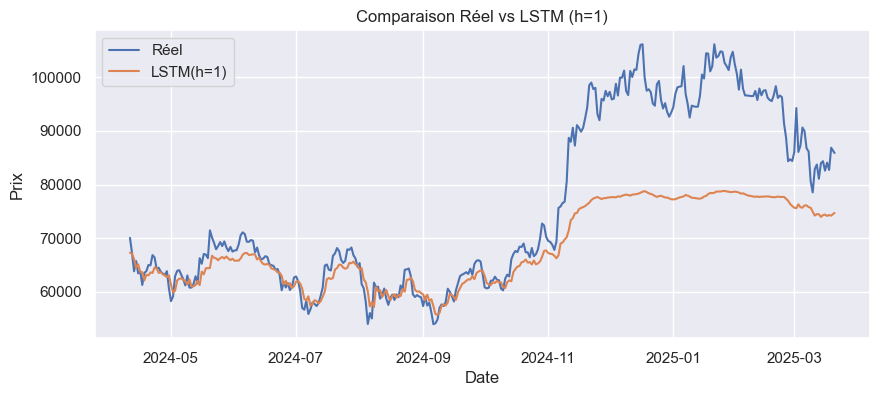

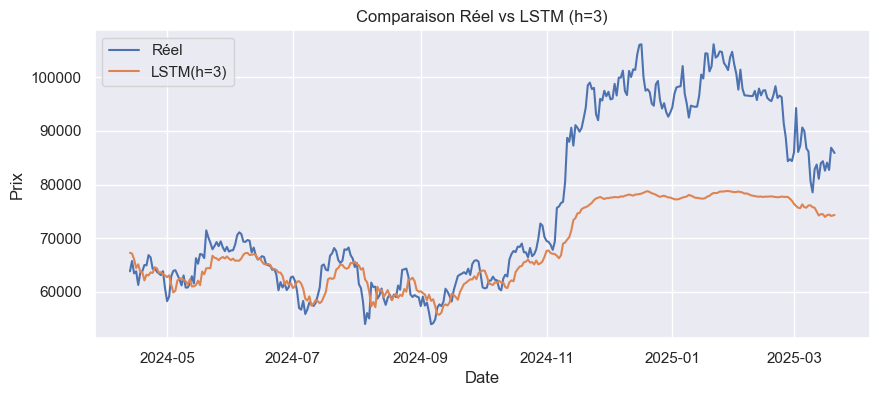

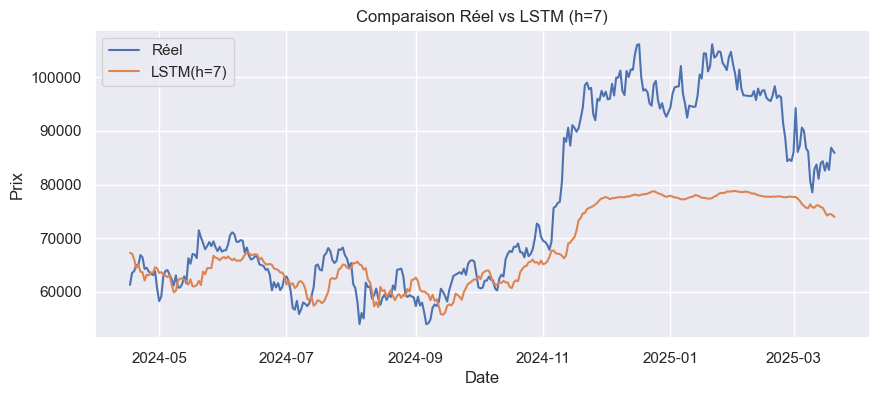

In [15]:
for horizon in horizons:
        data_h = datasets[horizon]
        X_test, y_test = data_h['X_test'], data_h['y_test']
        scaler = data_h['scaler']

        X_test_t, y_test_t = numpy_to_torch(X_test, y_test)
        test_ds = torch.utils.data.TensorDataset(X_test_t, y_test_t)
        test_loader = torch.utils.data.DataLoader(test_ds, batch_size=32, shuffle=False)

        lstm_preds, lstm_trues = predict(pretrained_lstm, test_loader)
        inv_lstm_preds = scaler.inverse_transform(lstm_preds)
        inv_lstm_trues = scaler.inverse_transform(lstm_trues)

        lstm_metrics = compute_metrics(inv_lstm_preds, inv_lstm_trues)
        # On l'appelle "LSTM_pretrained" pour le distinguer de "LSTM_from_scratch"
        results.append({"Model":"LSTM_pretrained", "Horizon":horizon, **lstm_metrics})

        # Petit plot
        test_dates = df_test.index[-len(test_ds):]
        if len(test_dates) == len(inv_lstm_preds):
            plot_prediction_lstm(
                test_dates,
                inv_lstm_trues.flatten(),
                inv_lstm_preds.flatten(),
                horizon
            )


=== Tableau final des résultats ===
                Model  Horizon           MAE          RMSE       MAPE        R2
0   LSTM_from_scratch        1   4155.479980   5958.728723   4.753965  0.863032
1                 GRU        1   3932.203369   5557.983987   4.492063  0.880836
2           Attention        1   6002.044922   9140.571098   6.601432  0.677701
3   LSTM_from_scratch        3   6341.873047   8529.106401   7.363424  0.720680
4                 GRU        3   6650.174805   8941.927309   7.703961  0.692987
5           Attention        3  13439.205078  19400.352986  14.890991 -0.445153
6   LSTM_from_scratch        7   7301.200684   9627.905276   8.606619  0.646070
7                 GRU        7   8690.443359  11385.109573  10.143445  0.505088
8           Attention        7  13472.721680  19230.173790  15.037905 -0.411952
9     LSTM_pretrained        1   8008.228027  11715.078830   8.861797  0.470577
10    LSTM_pretrained        3   8439.195312  11917.084207   9.515506  0.454701
11 

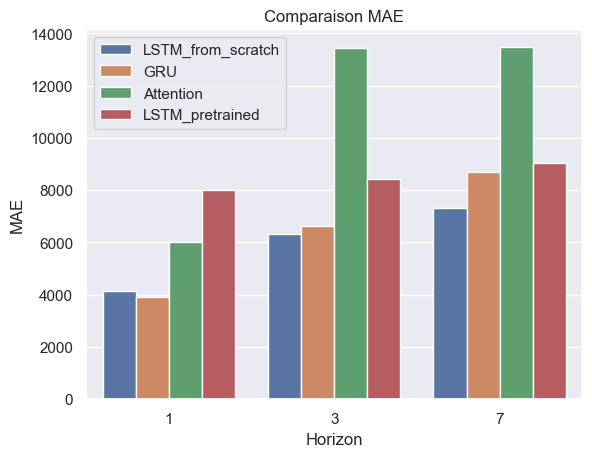

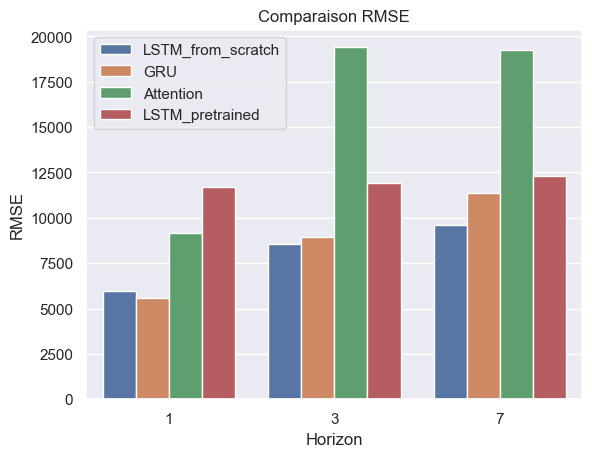

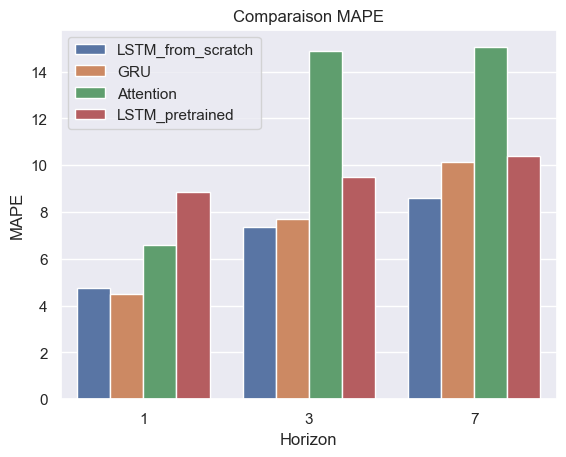

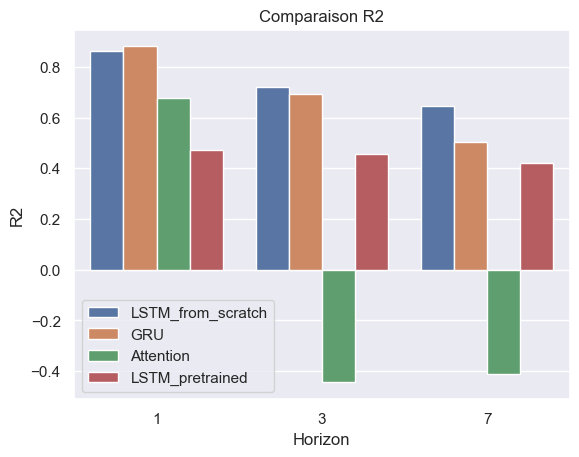

In [16]:
df_results = pd.DataFrame(results)
print("\n=== Tableau final des résultats ===")
print(df_results)

# Barplot comparatif
def barplot_metrics(df_results):
    metrics_list = ["MAE","RMSE","MAPE","R2"]
    for m in metrics_list:
        plt.figure()
        sns.barplot(data=df_results, x="Horizon", y=m, hue="Model")
        plt.title(f"Comparaison {m}")
        plt.legend()
        plt.show()

barplot_metrics(df_results)